In [1]:
import pandas as pd
import numpy as np
import sklearn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

try:
    import catboost
    print("CatBoost:", catboost.__version__)
except ImportError:
    print("CatBoost is NOT installed")

Pandas: 2.3.3
NumPy: 2.4.1
Scikit-learn: 1.7.1
CatBoost is NOT installed


In [2]:
%pip install catboost

   ---------------------------------------- 0.0/100.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/100.2 MB ? eta -:--:--
    --------------------------------------- 2.1/100.2 MB 9.0 MB/s eta 0:00:11
   - -------------------------------------- 5.0/100.2 MB 11.2 MB/s eta 0:00:09
   --- ------------------------------------ 7.6/100.2 MB 12.7 MB/s eta 0:00:08
   ---- ----------------------------------- 11.3/100.2 MB 13.3 MB/s eta 0:00:07
   ----- ---------------------------------- 14.7/100.2 MB 13.8 MB/s eta 0:00:07
   ------- -------------------------------- 17.6/100.2 MB 13.7 MB/s eta 0:00:07
   -------- ------------------------------- 20.4/100.2 MB 13.5 MB/s eta 0:00:06
   -------- ------------------------------- 22.5/100.2 MB 13.1 MB/s eta 0:00:06
   ---------- ----------------------------- 25.7/100.2 MB 13.2 MB/s eta 0:00:06
   ----------- ---------------------------- 28.3/100.2 MB 13.1 MB/s eta 0:00:06
   ------------ --------------------------- 31.2/100.2 MB 13.2

In [3]:
import catboost

print("CatBoost version:", catboost.__version__)
print("Installation successful!")

CatBoost version: 1.2.10
Installation successful!


In [4]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nFiles in data folder:")
for file in Path("../data").glob("*"):
    print(file.name)

Current working directory:
c:\Users\SALE\Desktop\ML Project\notebooks

Files in data folder:
diabetes+130-us+hospitals+for+years+1999-2008.zip


In [5]:
import zipfile

zip_path = "../data/diabetes+130-us+hospitals+for+years+1999-2008.zip"

with zipfile.ZipFile(zip_path, "r") as archive:
    print("Files inside the dataset:")
    for name in archive.namelist():
        print(name)

Files inside the dataset:
diabetic_data.csv
IDS_mapping.csv


In [6]:
import pandas as pd
import zipfile

zip_path = "../data/diabetes+130-us+hospitals+for+years+1999-2008.zip"

with zipfile.ZipFile(zip_path, "r") as archive:
    with archive.open("diabetic_data.csv") as file:
        df = pd.read_csv(file)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [7]:
print("Dataset columns:")
print(df.columns.tolist())

print("\nReadmission distribution:")
print(df["readmitted"].value_counts())

print("\nReadmission percentages:")
print(
    df["readmitted"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Dataset columns:
['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']

Readmission distribution:
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

Readmission percentages:
readmitted
NO     53.91
>30    34.93

In [8]:
# Convert the original 3-class target into binary classification

df["readmission_binary"] = (
    df["readmitted"] != "NO"
).astype(int)

print("New target distribution:")
print(df["readmission_binary"].value_counts())

print("\nPercentages:")
print(
    df["readmission_binary"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

New target distribution:
readmission_binary
0    54864
1    46902
Name: count, dtype: int64

Percentages:
readmission_binary
0    53.91
1    46.09
Name: proportion, dtype: float64


In [9]:
# Create a modelling copy
df_model = df.copy()

# Exclude expired and hospice discharge outcomes
excluded_dispositions = [11, 13, 14, 19, 20]

df_model = df_model[
    ~df_model["discharge_disposition_id"].isin(
        excluded_dispositions
    )
].copy()

# Remove previously identified unnecessary columns
df_model.drop(
    columns=["weight", "citoglipton", "examide"],
    inplace=True
)

# Convert unknown markers into missing values
df_model.replace("?", np.nan, inplace=True)

print("Original dataset:", df.shape)
print("Modelling dataset:", df_model.shape)
print("Excluded encounters:", len(df) - len(df_model))

Original dataset: (101766, 51)
Modelling dataset: (99343, 48)
Excluded encounters: 2423


In [10]:
# Identify categorical columns
categorical_cols = df_model.select_dtypes(
    include=["object"]
).columns.tolist()

# Fill missing categorical values
df_model[categorical_cols] = (
    df_model[categorical_cols].fillna("Unknown")
)

# Check remaining missing values
missing = df_model.isnull().sum()
print("Columns with remaining missing values:")
print(missing[missing > 0])


Columns with remaining missing values:
Series([], dtype: int64)


In [11]:

# Columns that should not be used as model features
drop_cols = [
    "encounter_id",
    "patient_nbr",
    "discharge_disposition_id",
    "payer_code",
    "readmitted",
    "readmission_binary"
]

# Separate features and target
X = df_model.drop(columns=drop_cols)
y = df_model["readmission_binary"]

# Keep patient IDs separately for grouped splitting
groups = df_model["patient_nbr"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Number of features:", X.shape[1])
print("\nTarget distribution:")
print(y.value_counts(normalize=True).round(3))


Feature shape: (99343, 42)
Target shape: (99343,)
Number of features: 42

Target distribution:
readmission_binary
0    0.529
1    0.471
Name: proportion, dtype: float64


In [12]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx]

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print(
    "Common patients:",
    len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]))
)


Training shape: (79541, 42)
Testing shape: (19802, 42)
Common patients: 0


In [13]:
# Identify categorical columns
cat_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

# These IDs represent categories, not numerical quantities
for col in ["admission_type_id", "admission_source_id"]:
    X_train[col] = X_train[col].astype(str)
    X_test[col] = X_test[col].astype(str)

    if col not in cat_features:
        cat_features.append(col)

print("Total categorical features:", len(cat_features))
print("\nCategorical features:")
print(cat_features)

print("\nNumerical features:", X_train.shape[1] - len(cat_features))


Total categorical features: 34

Categorical features:
['race', 'gender', 'age', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'admission_type_id', 'admission_source_id']

Numerical features: 8


In [14]:
from sklearn.model_selection import GroupShuffleSplit
from catboost import CatBoostClassifier

# Split training data into training and validation sets
val_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

sub_train_idx, val_idx = next(
    val_splitter.split(
        X_train, y_train, groups=groups_train
    )
)

X_subtrain = X_train.iloc[sub_train_idx]
X_val = X_train.iloc[val_idx]

y_subtrain = y_train.iloc[sub_train_idx]
y_val = y_train.iloc[val_idx]

# Train CatBoost
cat_model = CatBoostClassifier(
    iterations=700,
    learning_rate=0.05,
    depth=6,
    loss_function="Logloss",
    eval_metric="F1",
    random_seed=42,
    verbose=100,
    early_stopping_rounds=50,
    allow_writing_files=False
)

cat_model.fit(
    X_subtrain,
    y_subtrain,
    cat_features=cat_features,
    eval_set=(X_val, y_val)
)


0:	learn: 0.5084065	test: 0.4931098	best: 0.4931098 (0)	total: 400ms	remaining: 4m 39s
100:	learn: 0.5846480	test: 0.5582408	best: 0.5582408 (100)	total: 20s	remaining: 1m 58s
200:	learn: 0.5983368	test: 0.5677551	best: 0.5678105 (198)	total: 41.6s	remaining: 1m 43s
300:	learn: 0.6064925	test: 0.5738235	best: 0.5742274 (299)	total: 1m 3s	remaining: 1m 24s
400:	learn: 0.6128077	test: 0.5763359	best: 0.5763359 (400)	total: 1m 28s	remaining: 1m 6s
500:	learn: 0.6173233	test: 0.5768729	best: 0.5775015 (453)	total: 1m 53s	remaining: 45.1s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.5775015039
bestIteration = 453

Shrink model to first 454 iterations.


CatBoostClassifier(allow_writing_files=False, depth=6, early_stopping_rounds=50, eval_metric='F1', iterations=700, learning_rate=0.05, loss_function='Logloss', random_seed=42, verbose=100)

In [15]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# Predict on validation data
y_val_pred = cat_model.predict(X_val).ravel()

print("Validation Accuracy:",
      round(accuracy_score(y_val, y_val_pred), 4))

print("Validation F1:",
      round(f1_score(y_val, y_val_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred,
    target_names=["Not Readmitted", "Readmitted"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))


Validation Accuracy: 0.6409
Validation F1: 0.5775

Classification Report:
                precision    recall  f1-score   support

Not Readmitted       0.65      0.73      0.69      6379
    Readmitted       0.62      0.54      0.58      5357

      accuracy                           0.64     11736
     macro avg       0.64      0.63      0.63     11736
  weighted avg       0.64      0.64      0.64     11736

Confusion Matrix:
[[4642 1737]
 [2477 2880]]


                Feature  Importance
12     number_inpatient   20.469762
13               diag_1    8.473313
4   admission_source_id    6.521266
14               diag_2    5.250505
16     number_diagnoses    5.130512
6     medical_specialty    4.976455
3     admission_type_id    4.965487
9       num_medications    4.224684
11     number_emergency    4.068352
2                   age    4.044994
15               diag_3    3.812718
10    number_outpatient    3.552302
7    num_lab_procedures    3.371565
0                  race    2.352345
5      time_in_hospital    2.278823


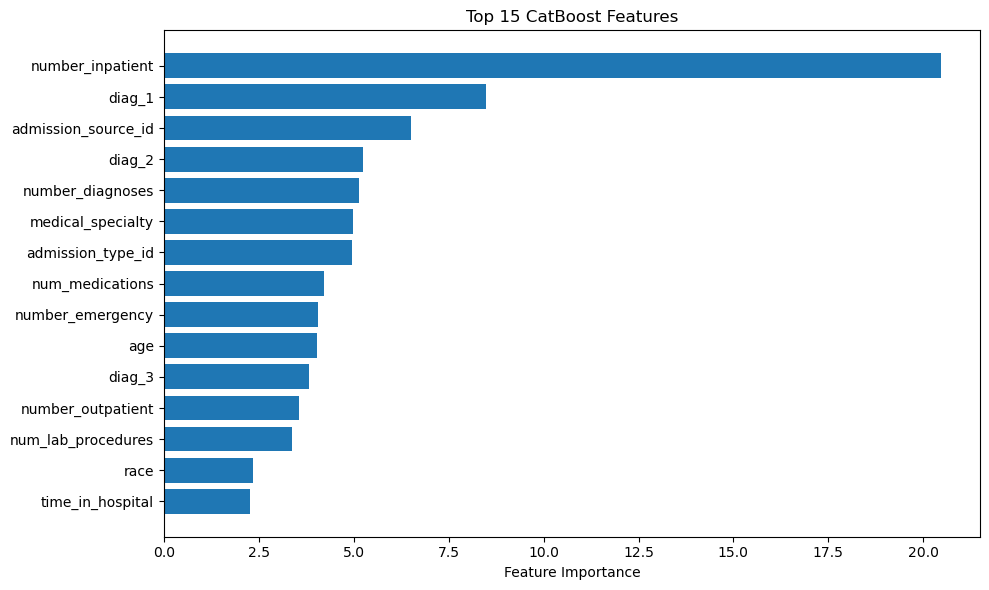

In [16]:

import pandas as pd
import matplotlib.pyplot as plt

importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": cat_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance.head(15))

plt.figure(figsize=(10, 6))
plt.barh(
    importance.head(15)["Feature"][::-1],
    importance.head(15)["Importance"][::-1]
)
plt.xlabel("Feature Importance")
plt.title("Top 15 CatBoost Features")
plt.tight_layout()
plt.show()


In [17]:

medication_features = [
    "metformin", "repaglinide", "nateglinide",
    "chlorpropamide", "glimepiride", "acetohexamide",
    "glipizide", "glyburide", "tolbutamide",
    "pioglitazone", "rosiglitazone", "acarbose",
    "miglitol", "troglitazone", "tolazamide",
    "insulin", "glyburide-metformin",
    "glipizide-metformin", "glimepiride-pioglitazone",
    "metformin-rosiglitazone", "metformin-pioglitazone",
    "change", "diabetesMed"
]

# Remove medication-related columns
X_train_reduced = X_train.drop(
    columns=medication_features
)

X_val_reduced = X_val.drop(
    columns=medication_features
)

# Update categorical feature list
cat_features_reduced = [
    col for col in cat_features
    if col not in medication_features
]

print("Original features:", X_train.shape[1])
print("Reduced features:", X_train_reduced.shape[1])
print("Removed features:", len(medication_features))


Original features: 42
Reduced features: 19
Removed features: 23


In [18]:

# Medication features we want to retain
keep_medications = [
    "insulin",
    "diabetesMed",
    "change"
]

# Remove other individual medication columns
medication_features = [
    col for col in [
        "metformin", "repaglinide", "nateglinide",
        "chlorpropamide", "glimepiride", "acetohexamide",
        "glipizide", "glyburide", "tolbutamide",
        "pioglitazone", "rosiglitazone", "acarbose",
        "miglitol", "troglitazone", "tolazamide",
        "glyburide-metformin", "glipizide-metformin",
        "glimepiride-pioglitazone",
        "metformin-rosiglitazone",
        "metformin-pioglitazone"
    ]
    if col not in keep_medications
]

# Create reduced datasets
X_train_reduced = X_train.drop(columns=medication_features)
X_val_reduced = X_val.drop(columns=medication_features)

cat_features_reduced = [
    col for col in cat_features
    if col not in medication_features
]

print("Original features:", X_train.shape[1])
print("Reduced features:", X_train_reduced.shape[1])
print("Removed features:", len(medication_features))
print("Retained medication features:", keep_medications)


Original features: 42
Reduced features: 22
Removed features: 20
Retained medication features: ['insulin', 'diabetesMed', 'change']


In [19]:

cat_model_reduced = CatBoostClassifier(
    iterations=700,
    learning_rate=0.05,
    depth=6,
    loss_function="Logloss",
    eval_metric="F1",
    random_seed=42,
    verbose=100,
    early_stopping_rounds=50,
    allow_writing_files=False
)

cat_model_reduced.fit(
    X_subtrain[X_train_reduced.columns],
    y_subtrain,
    cat_features=cat_features_reduced,
    eval_set=(
        X_val_reduced,
        y_val
    )
)


0:	learn: 0.5340666	test: 0.5186161	best: 0.5186161 (0)	total: 271ms	remaining: 3m 9s
100:	learn: 0.5856000	test: 0.5598424	best: 0.5598424 (100)	total: 19s	remaining: 1m 52s
200:	learn: 0.5991256	test: 0.5692449	best: 0.5695310 (182)	total: 39s	remaining: 1m 36s
300:	learn: 0.6069627	test: 0.5743476	best: 0.5746917 (298)	total: 59.4s	remaining: 1m 18s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.576041982
bestIteration = 316

Shrink model to first 317 iterations.


CatBoostClassifier(allow_writing_files=False, depth=6, early_stopping_rounds=50, eval_metric='F1', iterations=700, learning_rate=0.05, loss_function='Logloss', random_seed=42, verbose=100)

In [20]:

from sklearn.metrics import accuracy_score, f1_score

# Predictions
pred_full = cat_model.predict(X_val)
pred_reduced = cat_model_reduced.predict(X_val_reduced)

comparison = pd.DataFrame({
    "Model": ["Full CatBoost (42)", "Reduced CatBoost (22)"],
    "Accuracy": [
        accuracy_score(y_val, pred_full),
        accuracy_score(y_val, pred_reduced)
    ],
    "F1 Score": [
        f1_score(y_val, pred_full),
        f1_score(y_val, pred_reduced)
    ]
})

print(comparison.round(4))


                   Model  Accuracy  F1 Score
0     Full CatBoost (42)    0.6409    0.5775
1  Reduced CatBoost (22)    0.6420    0.5760


In [21]:

print(comparison.round(4).to_string(index=False))


                Model  Accuracy  F1 Score
   Full CatBoost (42)    0.6409    0.5775
Reduced CatBoost (22)    0.6420    0.5760


In [22]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Use the reduced model on untouched test data
X_test_reduced = X_test[X_train_reduced.columns]

y_test_pred = cat_model_reduced.predict(
    X_test_reduced
).ravel()

print("TEST ACCURACY:",
      round(accuracy_score(y_test, y_test_pred), 4))

print("TEST F1 SCORE:",
      round(f1_score(y_test, y_test_pred), 4))

print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Not Readmitted", "Readmitted"]
))

print("\nCONFUSION MATRIX:")
print(confusion_matrix(y_test, y_test_pred))


TEST ACCURACY: 0.6369
TEST F1 SCORE: 0.5846

CLASSIFICATION REPORT:
                precision    recall  f1-score   support

Not Readmitted       0.64      0.72      0.68     10496
    Readmitted       0.63      0.54      0.58      9306

      accuracy                           0.64     19802
     macro avg       0.64      0.63      0.63     19802
  weighted avg       0.64      0.64      0.63     19802


CONFUSION MATRIX:
[[7552 2944]
 [4247 5059]]


In [23]:
import os
import json

# Create models folder if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Save trained model
model_path = "../models/carecontinuum_catboost.cbm"
cat_model_reduced.save_model(model_path)

# Save model input information
metadata = {
    "feature_columns": X_train_reduced.columns.tolist(),
    "categorical_features": cat_features_reduced,
    "target": "readmission_binary",
    "class_mapping": {
        "0": "Not Readmitted",
        "1": "Readmitted"
    },
    "prediction_threshold": 0.5
}

metadata_path = "../models/model_metadata.json"

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print("Model saved:", os.path.exists(model_path))
print("Metadata saved:", os.path.exists(metadata_path))
print("Number of features:", len(metadata["feature_columns"]))


Model saved: True
Metadata saved: True
Number of features: 22


In [24]:
%pip install streamlit

   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
   -- ------------------------------------- 0.8/11.2 MB 5.6 MB/s eta 0:00:02
   --------------- ------------------------ 4.5/11.2 MB 13.4 MB/s eta 0:00:01
   -------------------------------- ------- 9.2/11.2 MB 17.3 MB/s eta 0:00:01
   ---------------------------------------  11.0/11.2 MB 18.1 MB/s eta 0:00:01
   ---------------------------------------- 11.2/11.2 MB 12.3 MB/s  0:00:00
   ---------------------------------------- 0.0/797.2 kB ? eta -:--:--
   ---------------------------------------- 797.2/797.2 kB 16.7 MB/s  0:00:00
   ---------------------------------------- 0.0/29.0 MB ? eta -:--:--
   --- ------------------------------------ 2.9/29.0 MB 24.0 MB/s eta 0:00:02
   ------ --------------------------------- 5.0/29.0 MB 11.6 MB/s eta 0:00:03
   -------------- ------------------------- 10.5/29.0 MB 16.8 MB/s eta 0:00:02
   ------------------ --------------------- 13.4/29.0 MB 17.1 MB/s eta 0:00:01
   ------

In [25]:
import sys
print(sys.executable)

c:\Users\SALE\anaconda3.1\envs\course_env\python.exe


In [26]:

import json

# Collect valid categories from training data
category_options = {}

for col in cat_features_reduced:
    category_options[col] = sorted(
        X_train_reduced[col].astype(str).unique().tolist()
    )

# Save category options for the website
with open("../models/category_options.json", "w") as f:
    json.dump(category_options, f, indent=4)

print("Category options saved successfully!")

for col, values in category_options.items():
    print(col, ":", len(values), "options")


Category options saved successfully!
race : 6 options
gender : 3 options
age : 10 options
medical_specialty : 73 options
diag_1 : 701 options
diag_2 : 719 options
diag_3 : 761 options
max_glu_serum : 4 options
A1Cresult : 4 options
insulin : 4 options
change : 2 options
diabetesMed : 2 options
admission_type_id : 8 options
admission_source_id : 17 options


In [27]:

numeric_features = [
    col for col in X_train_reduced.columns
    if col not in cat_features_reduced
]

numeric_stats = {}

for col in numeric_features:
    numeric_stats[col] = {
        "min": int(X_train_reduced[col].min()),
        "max": int(X_train_reduced[col].max()),
        "median": int(X_train_reduced[col].median())
    }

with open("../models/numeric_stats.json", "w") as f:
    json.dump(numeric_stats, f, indent=4)

print("Numerical statistics saved!")
print(json.dumps(numeric_stats, indent=4))


Numerical statistics saved!
{
    "time_in_hospital": {
        "min": 1,
        "max": 14,
        "median": 4
    },
    "num_lab_procedures": {
        "min": 1,
        "max": 132,
        "median": 44
    },
    "num_procedures": {
        "min": 0,
        "max": 6,
        "median": 1
    },
    "num_medications": {
        "min": 1,
        "max": 81,
        "median": 15
    },
    "number_outpatient": {
        "min": 0,
        "max": 40,
        "median": 0
    },
    "number_emergency": {
        "min": 0,
        "max": 76,
        "median": 0
    },
    "number_inpatient": {
        "min": 0,
        "max": 21,
        "median": 0
    },
    "number_diagnoses": {
        "min": 1,
        "max": 16,
        "median": 8
    }
}


In [28]:

# Select the 10 most important features
compact_features = [
    "number_inpatient",
    "diag_1",
    "admission_source_id",
    "diag_2",
    "number_diagnoses",
    "medical_specialty",
    "admission_type_id",
    "num_medications",
    "number_emergency",
    "age"
]

# Create compact training and validation datasets
X_subtrain_10 = X_subtrain[compact_features].copy()
X_val_10 = X_val[compact_features].copy()

# Identify categorical features
cat_features_10 = [
    col for col in compact_features
    if col in cat_features_reduced
]

print("Number of features:", len(compact_features))
print("Training shape:", X_subtrain_10.shape)
print("Validation shape:", X_val_10.shape)
print("Categorical features:", cat_features_10)


Number of features: 10
Training shape: (67805, 10)
Validation shape: (11736, 10)
Categorical features: ['diag_1', 'admission_source_id', 'diag_2', 'medical_specialty', 'admission_type_id', 'age']


In [29]:

compact_features = [
    "number_inpatient",
    "diag_1",
    "admission_source_id",
    "diag_2",
    "number_diagnoses",
    "medical_specialty",
    "admission_type_id",
    "num_medications",
    "number_emergency",
    "age"
]

X_subtrain_10 = X_subtrain[compact_features].copy()
X_val_10 = X_val[compact_features].copy()

cat_features_10 = [
    col for col in compact_features
    if col in cat_features_reduced
]

print("Features:", len(compact_features))
print("Training shape:", X_subtrain_10.shape)
print("Validation shape:", X_val_10.shape)
print("Categorical features:", cat_features_10)


Features: 10
Training shape: (67805, 10)
Validation shape: (11736, 10)
Categorical features: ['diag_1', 'admission_source_id', 'diag_2', 'medical_specialty', 'admission_type_id', 'age']


In [30]:

cat_model_10_baseline = CatBoostClassifier(
    iterations=700,
    learning_rate=0.05,
    depth=6,
    loss_function="Logloss",
    eval_metric="F1",
    random_seed=42,
    verbose=100,
    early_stopping_rounds=50,
    allow_writing_files=False
)

cat_model_10_baseline.fit(
    X_subtrain_10,
    y_subtrain,
    cat_features=cat_features_10,
    eval_set=(X_val_10, y_val)
)


0:	learn: 0.5439275	test: 0.5286713	best: 0.5286713 (0)	total: 106ms	remaining: 1m 13s
100:	learn: 0.5781213	test: 0.5572480	best: 0.5575130 (97)	total: 10.1s	remaining: 1m
200:	learn: 0.5913953	test: 0.5663500	best: 0.5663500 (200)	total: 19.8s	remaining: 49.2s
300:	learn: 0.5964671	test: 0.5684445	best: 0.5684445 (300)	total: 30.1s	remaining: 40s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.5695176328
bestIteration = 321

Shrink model to first 322 iterations.


CatBoostClassifier(allow_writing_files=False, depth=6, early_stopping_rounds=50, eval_metric='F1', iterations=700, learning_rate=0.05, loss_function='Logloss', random_seed=42, verbose=100)

In [31]:

from sklearn.metrics import accuracy_score, f1_score

pred_22 = cat_model_reduced.predict(X_val_reduced)
pred_10 = cat_model_10_baseline.predict(X_val_10)

comparison = pd.DataFrame({
    "Model": ["22 Features", "10 Features"],
    "Accuracy": [
        accuracy_score(y_val, pred_22),
        accuracy_score(y_val, pred_10)
    ],
    "F1 Score": [
        f1_score(y_val, pred_22),
        f1_score(y_val, pred_10)
    ]
})

print(comparison.round(4).to_string(index=False))


      Model  Accuracy  F1 Score
22 Features     0.642    0.5760
10 Features     0.638    0.5695


In [32]:
from itertools import product

configurations = list(product(
    [4, 6],       # depth
    [0.03, 0.05], # learning rate
    [3, 5]        # L2 regularization
))

print("Total configurations:", len(configurations))

for i, config in enumerate(configurations, 1):
    print(
        f"{i}. depth={config[0]}, "
        f"learning_rate={config[1]}, "
        f"l2_leaf_reg={config[2]}"
    )

Total configurations: 8
1. depth=4, learning_rate=0.03, l2_leaf_reg=3
2. depth=4, learning_rate=0.03, l2_leaf_reg=5
3. depth=4, learning_rate=0.05, l2_leaf_reg=3
4. depth=4, learning_rate=0.05, l2_leaf_reg=5
5. depth=6, learning_rate=0.03, l2_leaf_reg=3
6. depth=6, learning_rate=0.03, l2_leaf_reg=5
7. depth=6, learning_rate=0.05, l2_leaf_reg=3
8. depth=6, learning_rate=0.05, l2_leaf_reg=5


In [33]:
from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)
import pandas as pd

results = []
models_10 = []

for i, (depth, learning_rate, l2_leaf_reg) in enumerate(configurations, 1):

    print(f"\nTraining model {i}/8")
    print(
        f"depth={depth}, learning_rate={learning_rate}, "
        f"l2_leaf_reg={l2_leaf_reg}"
    )

    model = CatBoostClassifier(
        iterations=700,
        learning_rate=learning_rate,
        depth=depth,
        l2_leaf_reg=l2_leaf_reg,
        loss_function="Logloss",
        eval_metric="F1",
        random_seed=42,
        verbose=False,
        early_stopping_rounds=50,
        allow_writing_files=False
    )

    model.fit(
        X_subtrain_10,
        y_subtrain,
        cat_features=cat_features_10,
        eval_set=(X_val_10, y_val),
        verbose=False
    )

    predictions = model.predict(X_val_10)

    results.append({
        "Model": i,
        "Depth": depth,
        "Learning Rate": learning_rate,
        "L2": l2_leaf_reg,
        "Best Iteration": model.best_iteration_,
        "Accuracy": accuracy_score(y_val, predictions),
        "F1": f1_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions)
    })

    models_10.append(model)

results_df = pd.DataFrame(results)

print("\nHYPERPARAMETER COMPARISON")
display(
    results_df.sort_values("F1", ascending=False).round(4)
)


Training model 1/8
depth=4, learning_rate=0.03, l2_leaf_reg=3

Training model 2/8
depth=4, learning_rate=0.03, l2_leaf_reg=5

Training model 3/8
depth=4, learning_rate=0.05, l2_leaf_reg=3

Training model 4/8
depth=4, learning_rate=0.05, l2_leaf_reg=5

Training model 5/8
depth=6, learning_rate=0.03, l2_leaf_reg=3

Training model 6/8
depth=6, learning_rate=0.03, l2_leaf_reg=5

Training model 7/8
depth=6, learning_rate=0.05, l2_leaf_reg=3

Training model 8/8
depth=6, learning_rate=0.05, l2_leaf_reg=5

HYPERPARAMETER COMPARISON


,Model,Depth,Learning Rate,L2,Best Iteration,Accuracy,F1,Precision,Recall
7,8,6,0.05,5,484,0.6380,0.5727,0.6209,0.5315
6,7,6,0.05,3,321,0.6380,0.5695,0.6229,0.5245
2,3,4,0.05,3,425,0.6389,0.5678,0.6258,0.5197
3,4,4,0.05,5,295,0.6352,0.5619,0.6219,0.5124
0,1,4,0.03,3,334,0.6368,0.5602,0.6264,0.5066
5,6,6,0.03,5,2,0.6256,0.5305,0.6203,0.4633
4,5,6,0.03,3,2,0.6256,0.5305,0.6203,0.4633
1,2,4,0.03,5,4,0.6221,0.5209,0.6182,0.4501


In [34]:
best_10_model = models_10[7]

print("Best 10-feature model:")
print("Depth:", best_10_model.get_param("depth"))
print("Learning rate:", best_10_model.get_param("learning_rate"))
print("L2:", best_10_model.get_param("l2_leaf_reg"))
print("Best iteration:", best_10_model.best_iteration_)


Best 10-feature model:
Depth: 6
Learning rate: 0.05
L2: 5
Best iteration: 484


In [35]:
from catboost import CatBoostClassifier

final_model_10 = CatBoostClassifier(
    iterations=484,
    learning_rate=0.05,
    depth=6,
    l2_leaf_reg=5,
    loss_function="Logloss",
    eval_metric="F1",
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)

final_model_10.fit(
    X_train[compact_features],
    y_train,
    cat_features=cat_features_10
)

print("Final 10-feature model trained successfully!")

0:	learn: 0.5124374	total: 306ms	remaining: 2m 27s
100:	learn: 0.5697555	total: 21.5s	remaining: 1m 21s
200:	learn: 0.5817423	total: 38.4s	remaining: 54.1s
300:	learn: 0.5857197	total: 56.7s	remaining: 34.5s
400:	learn: 0.5898540	total: 1m 14s	remaining: 15.4s
483:	learn: 0.5926828	total: 1m 28s	remaining: 0us
Final 10-feature model trained successfully!


In [36]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)

X_test_10 = X_test[compact_features]

predictions_10 = final_model_10.predict(X_test_10)

print("FINAL 10-FEATURE MODEL — TEST RESULTS")
print("-------------------------------------")

print("Accuracy:", round(accuracy_score(y_test, predictions_10), 4))
print("F1 Score:", round(f1_score(y_test, predictions_10), 4))
print("Precision:", round(precision_score(y_test, predictions_10), 4))
print("Recall:", round(recall_score(y_test, predictions_10), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predictions_10))

print("\nClassification Report:")
print(classification_report(
    y_test,
    predictions_10,
    target_names=["Not Readmitted", "Readmitted"]
))

FINAL 10-FEATURE MODEL — TEST RESULTS
-------------------------------------
Accuracy: 0.6346
F1 Score: 0.5836
Precision: 0.6282
Recall: 0.5449

Confusion Matrix:
[[7495 3001]
 [4235 5071]]

Classification Report:
                precision    recall  f1-score   support

Not Readmitted       0.64      0.71      0.67     10496
    Readmitted       0.63      0.54      0.58      9306

      accuracy                           0.63     19802
     macro avg       0.63      0.63      0.63     19802
  weighted avg       0.63      0.63      0.63     19802



In [37]:
import os
import json
import numpy as np

# Create models folder if it doesn't exist
os.makedirs("../models", exist_ok=True)

# 1. Save the trained model
final_model_10.save_model(
    "../models/carecontinuum_catboost_10features.cbm"
)

# 2. Save model metadata
metadata_10 = {
    "model_name": "CareContinuum AI - Compact Model",
    "model_type": "CatBoostClassifier",
    "feature_columns": compact_features,
    "categorical_features": cat_features_10,
    "target": "readmission_binary",
    "class_mapping": {
        "0": "Not Readmitted",
        "1": "Readmitted"
    },
    "prediction_threshold": 0.5,
    "iterations": 484,
    "depth": 6,
    "learning_rate": 0.05,
    "l2_leaf_reg": 5
}

with open("../models/model_metadata_10features.json", "w") as f:
    json.dump(metadata_10, f, indent=4)

# 3. Save categorical input options
category_options_10 = {}

for col in cat_features_10:
    category_options_10[col] = sorted(
        X_train[col].dropna().astype(str).unique().tolist()
    )

with open("../models/category_options_10features.json", "w") as f:
    json.dump(category_options_10, f, indent=4)

print("Model saved:", os.path.exists(
    "../models/carecontinuum_catboost_10features.cbm"
))

print("Metadata saved:", os.path.exists(
    "../models/model_metadata_10features.json"
))

print("Category options saved:", os.path.exists(
    "../models/category_options_10features.json"
))

print("Number of features:", len(compact_features))

Model saved: True
Metadata saved: True
Category options saved: True
Number of features: 10


In [38]:
from catboost import CatBoostClassifier
import numpy as np

# Load the saved model
loaded_model_10 = CatBoostClassifier()

loaded_model_10.load_model(
    "../models/carecontinuum_catboost_10features.cbm"
)

# Generate predictions using both models
original_predictions = final_model_10.predict(X_test_10)
loaded_predictions = loaded_model_10.predict(X_test_10)

# Verify predictions match
print(
    "Predictions match:",
    np.array_equal(original_predictions, loaded_predictions)
)

print("Loaded model features:", loaded_model_10.feature_names_)
print("Number of features:", len(loaded_model_10.feature_names_))

Predictions match: True
Loaded model features: ['number_inpatient', 'diag_1', 'admission_source_id', 'diag_2', 'number_diagnoses', 'medical_specialty', 'admission_type_id', 'num_medications', 'number_emergency', 'age']
Number of features: 10


In [39]:
import pandas as pd

importance = final_model_10.get_feature_importance()

feature_importance_df = pd.DataFrame({
    "Feature": compact_features,
    "Importance": importance
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance_df.round(3))

,Feature,Importance
0,number_inpatient,24.913
1,diag_1,12.616
2,admission_source_id,9.974
3,diag_2,9.382
9,age,8.119
6,admission_type_id,7.914
4,number_diagnoses,7.560
5,medical_specialty,6.734
7,num_medications,6.525
8,number_emergency,6.264


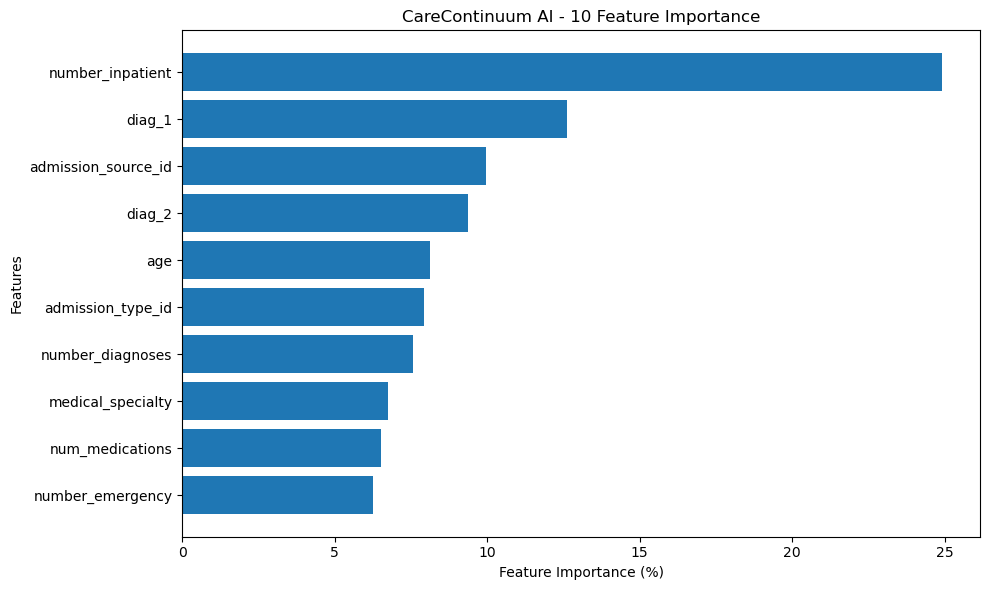

Chart saved successfully!


In [40]:
import matplotlib.pyplot as plt
import os

# Create documentation folder
os.makedirs("../docs", exist_ok=True)

# Plot feature importance
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance_df["Feature"],
    feature_importance_df["Importance"]
)

plt.xlabel("Feature Importance (%)")
plt.ylabel("Features")
plt.title("CareContinuum AI - 10 Feature Importance")

plt.gca().invert_yaxis()
plt.tight_layout()

# Save chart
plt.savefig(
    "../docs/feature_importance_10features.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully!")


## Dataset Acknowledgement

This project uses the Diabetes 130-US Hospitals for Years 1999–2008 dataset from the UCI Machine Learning Repository.

Clore, J., Cios, K., DeShazo, J., & Strack, B. (2014).
Diabetes 130-US Hospitals for Years 1999–2008 [Dataset].
UCI Machine Learning Repository.

https://doi.org/10.24432/C5230J

Dataset licence: Creative Commons Attribution 4.0 International (CC BY 4.0).

## Research Reference

Strack, B., DeShazo, J. P., Gennings, C., Olmo, J. L.,
Ventura, S., Cios, K. J., & Clore, J. N. (2014).

Impact of HbA1c Measurement on Hospital Readmission Rates:
Analysis of 70,000 Clinical Database Patient Records.

BioMed Research International, 2014, Article 781670.

https://doi.org/10.1155/2014/781670

## Machine Learning Reference

Prokhorenkova, L., Gusev, G., Vorobev, A.,
Dorogush, A. V., & Gulin, A. (2018).

CatBoost: Unbiased Boosting with Categorical Features.
Advances in Neural Information Processing Systems 31.

https://proceedings.neurips.cc/paper/2018/hash/14491b756b3a51daac41c24863285549-Abstract.html
